# Partie 1 — Météo (NOAA Global Hourly)
**Objectif** : à partir des observations horaires NOAA nettoyées, répondre à 4 questions : anomalies de température, météo × visibilité, saisonnalité, jours extrêmes.

Conventions : `city` = noms exacts de `config.py` ; `hour` = heure UTC (`.dt.floor("h")`) ; les agrégats journaliers sont calculés en **heure de Paris**.

In [1]:
import sys, warnings, importlib.util
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
FIG = ROOT / "figures"; FIG.mkdir(exist_ok=True)

# Charte graphique de Redouane (figures/style.py) : on tente d'appeler sa fonction d'initialisation
try:
    spec = importlib.util.spec_from_file_location("style", ROOT / "figures" / "style.py")
    style = importlib.util.module_from_spec(spec); spec.loader.exec_module(style)
    for _fn in ("apply", "set_style", "use", "setup", "init", "apply_style"):
        if hasattr(style, _fn):
            getattr(style, _fn)(); break
except Exception as e:
    print("style.py non chargé :", e); sns.set_theme(style="whitegrid")

PREFIX = "p1"
def save(fig, name):
    fig.savefig(FIG / f"{PREFIX}_{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

style.py non chargé : [Errno 2] No such file or directory: 'D:\\IPSSI FRANCE COURS\\DATA LAKE\\Projet-Urbanhub\\figures\\style.py'


## 0. Chargement et vérifications
⚠️ Adapter le dictionnaire `COL` aux noms réels des colonnes de `weather_city_hourly.parquet` (la cellule suivante affiche les colonnes et s'arrête si un nom est introuvable).

In [2]:
PATH = ROOT / "data" / "clean" / "weather_city_hourly.parquet"
COL = dict(temp="temp_c", wind="wind_ms", pres="slp_hpa", vis="vis_km",
           precip="precip_mm", period="precip_period_h")
PARIS = "Paris"

df = pd.read_parquet(PATH)
print(df.shape); print(df.columns.tolist())
missing = [c for c in COL.values() if c not in df.columns]
assert not missing, f"Colonnes introuvables {missing} -> adapter le dict COL ci-dessus"
assert PARIS in df["city"].unique(), f"Villes disponibles : {df['city'].unique()}"

try:
    from urbanhub_utils import check_city_hourly
    check_city_hourly(df)
except Exception as e:
    print("check_city_hourly :", e)

print("\nPériode UTC :", df["hour"].min(), "->", df["hour"].max())
print("\nTaux de valeurs manquantes (%) :")
print((df[list(COL.values())].isna().mean() * 100).round(1))

(320890, 9)
['city', 'hour', 'temp_c', 'wind_ms', 'slp_hpa', 'vis_km', 'precip_mm', 'precip_period_h', 'n_stations']
check_city_hourly : No module named 'urbanhub_utils'

Période UTC : 2021-01-01 00:00:00+00:00 -> 2025-08-24 21:00:00+00:00

Taux de valeurs manquantes (%) :
temp_c              0.1
wind_ms             0.0
slp_hpa            13.6
vis_km              0.0
precip_mm          42.4
precip_period_h    42.4
dtype: float64


In [3]:
T, W, P, V, PR, PP = (COL[k] for k in ("temp", "wind", "pres", "vis", "precip", "period"))

df["hour"] = pd.to_datetime(df["hour"], utc=True)
df["local"] = df["hour"].dt.tz_convert("Europe/Paris").dt.tz_localize(None)   # heure de Paris (naïve)
df["date"] = df["local"].dt.normalize()
# Précipitations : on ne garde que les cumuls sur 1 h (sinon double comptage des cumuls 3 h / 6 h / 24 h)
df["precip_1h"] = df[PR].where(df[PP] == 1)

g = df.groupby(["city", "date"])
daily = g.agg(tmean=(T, "mean"), tmax=(T, "max"), tmin=(T, "min"),
              wind_max=(W, "max"), wind_mean=(W, "mean"),
              vis_mean=(V, "mean"), pres_mean=(P, "mean"), n_obs=(T, "count")).reset_index()
daily = daily.merge(g["precip_1h"].sum(min_count=1).rename("precip").reset_index(), on=["city", "date"])
daily = daily[daily["n_obs"] >= 18].copy()          # jours avec au moins 18 h de mesures
daily["month"] = daily["date"].dt.month
daily["year"] = daily["date"].dt.year
print("Lignes journalières :", len(daily), "| villes :", daily["city"].nunique())
daily.head()

Lignes journalières : 13362 | villes : 8


,city,date,tmean,tmax,tmin,wind_max,wind_mean,vis_mean,pres_mean,n_obs,precip,month,year
0,Bordeaux,2021-01-01,2.302899,4.966667,0.000000,6.166667,3.300000,6.027362,1008.226087,23,4.4,1,2021
1,Bordeaux,2021-01-02,0.993056,4.000000,-2.100000,5.700000,3.493056,12.730125,1015.233333,24,0.0,1,2021
2,Bordeaux,2021-01-03,2.994444,7.433333,-0.033333,5.833333,3.938889,14.955208,1013.191667,24,4.0,1,2021
3,Bordeaux,2021-01-04,1.908333,4.100000,-1.000000,4.933333,3.262500,9.730125,1010.862500,24,0.0,1,2021
4,Bordeaux,2021-01-05,1.681944,3.100000,-1.166667,4.100000,1.912500,7.449708,1013.770833,24,0.0,1,2021


## Q1 — Anomalies de température (z-score)
**Méthode** : pour chaque ville et chaque mois calendaire, moyenne μ et écart-type σ de `tmean` ; z = (tmean − μ) / σ ; anomalie si |z| > 2,5.

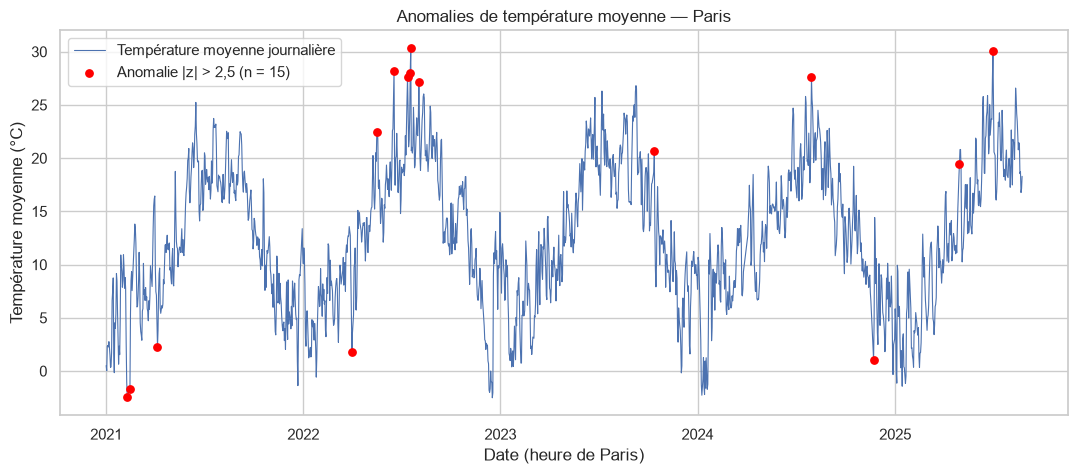

CHIFFRE CLÉ — anomalies par ville :
city
Bordeaux       9
Lille         13
Lyon           7
Marseille     10
Nantes        18
Paris         15
Strasbourg    10
Toulouse      17
dtype: int64

Anomalies chaudes / froides : 60 / 39

Top 10 anomalies (|z|) :
      city       date  tmean    mu     z
     Lille 2022-07-19  29.98 19.42  4.06
    Nantes 2022-07-18  31.27 19.99  3.91
     Lille 2025-07-01  29.21 19.42  3.77
     Paris 2022-07-19  30.37 20.30  3.54
     Paris 2025-07-01  30.10 20.30  3.44
     Lille 2021-02-09  -5.07  6.53 -3.28
  Toulouse 2023-03-01   1.70 10.67 -3.26
  Bordeaux 2022-07-18  31.76 22.11  3.23
Strasbourg 2021-02-14  -5.38  5.88 -3.14
  Toulouse 2022-04-03   3.21 12.75 -3.11


In [4]:
st = daily.groupby(["city", "month"])["tmean"].agg(mu="mean", sigma="std").reset_index()
daily = daily.merge(st, on=["city", "month"]).sort_values(["city", "date"])
daily["z"] = (daily["tmean"] - daily["mu"]) / daily["sigma"]
anom = daily[daily["z"].abs() > 2.5]

par = daily[daily["city"] == PARIS]
a = par[par["z"].abs() > 2.5]
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(par["date"], par["tmean"], lw=0.8, label="Température moyenne journalière")
ax.scatter(a["date"], a["tmean"], c="red", s=28, zorder=3, label=f"Anomalie |z| > 2,5 (n = {len(a)})")
ax.set(title=f"Anomalies de température moyenne — {PARIS}", xlabel="Date (heure de Paris)", ylabel="Température moyenne (°C)")
ax.legend(); save(fig, "q1_anomalies_paris")

print("CHIFFRE CLÉ — anomalies par ville :"); print(anom.groupby("city").size())
print(f"\nAnomalies chaudes / froides : {(anom.z > 0).sum()} / {(anom.z < 0).sum()}")
print("\nTop 10 anomalies (|z|) :")
print(anom.assign(absz=anom.z.abs()).sort_values("absz", ascending=False)
          [["city", "date", "tmean", "mu", "z"]].head(10).round(2).to_string(index=False))

**Q1 — Méthode → chiffre clé → interprétation**
- Méthode : z-score vs normale du mois et de la ville, seuil |z| > 2,5.
- Chiffre clé : [À COMPLÉTER : nombre d'anomalies Paris / total, date la plus extrême et son z].
- Interprétation : [À COMPLÉTER en 2–3 phrases : chaud vs froid, saisons concernées, lien avec événements connus].

## Q2 — Météo × visibilité
**Méthode** : corrélations de Spearman (robustes aux distributions asymétriques de la pluie et de la visibilité), comparaison de la visibilité par temps de pluie / sec, et fréquence du brouillard (visibilité < 1 km et vent faible < 2 m/s).

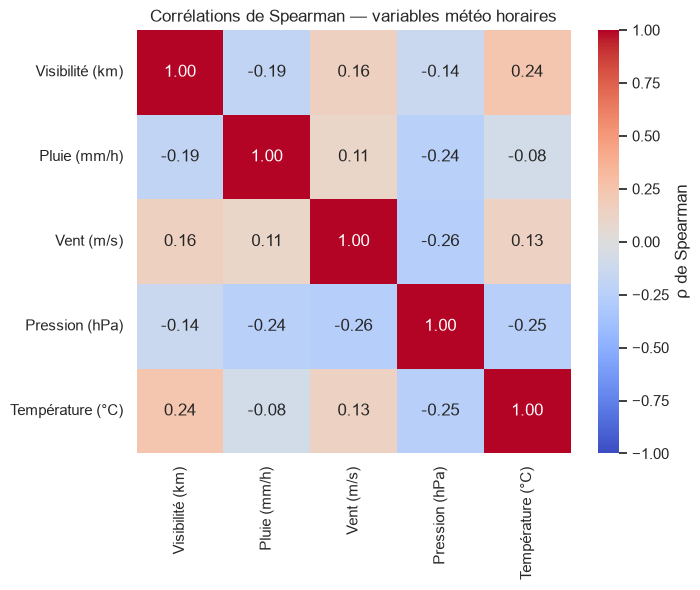

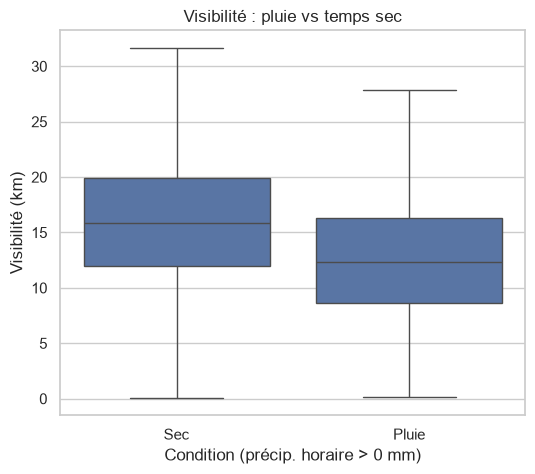

CHIFFRE CLÉ — visibilité médiane (km) : {'Pluie': 12.3, 'Sec': 15.9}
Spearman visibilité~pluie : -0.19


In [5]:
cols = {V: "Visibilité (km)", "precip_1h": "Pluie (mm/h)", W: "Vent (m/s)", P: "Pression (hPa)", T: "Température (°C)"}
corr = df[list(cols)].rename(columns=cols).corr(method="spearman")
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax, cbar_kws={"label": "ρ de Spearman"})
ax.set_title("Corrélations de Spearman — variables météo horaires"); save(fig, "q2_heatmap_spearman")

sub = df.dropna(subset=[V, "precip_1h"]).copy()
sub["Condition"] = np.where(sub["precip_1h"] > 0, "Pluie", "Sec")
fig, ax = plt.subplots(figsize=(6, 5))
sns.boxplot(data=sub, x="Condition", y=V, showfliers=False, ax=ax)
ax.set(title="Visibilité : pluie vs temps sec", xlabel="Condition (précip. horaire > 0 mm)", ylabel="Visibilité (km)")
save(fig, "q2_boxplot_visibilite_pluie")
med = sub.groupby("Condition")[V].median()
print("CHIFFRE CLÉ — visibilité médiane (km) :", med.round(1).to_dict())
print("Spearman visibilité~pluie :", round(corr.loc["Visibilité (km)", "Pluie (mm/h)"], 2))

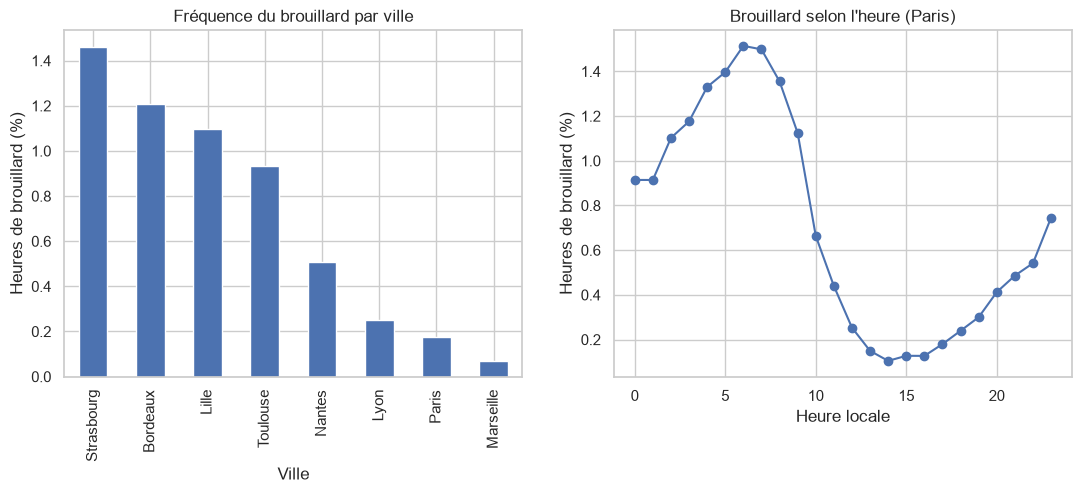

CHIFFRE CLÉ — brouillard (%) par ville :
city
Strasbourg    1.46
Bordeaux      1.21
Lille         1.10
Toulouse      0.93
Nantes        0.51
Lyon          0.25
Paris         0.17
Marseille     0.07
Name: fog, dtype: float64
Heure locale la plus brumeuse : 6 h


In [6]:
df["fog"] = (df[V] < 1) & (df[W] < 2)
fog_city = (df.dropna(subset=[V, W]).groupby("city")["fog"].mean() * 100).sort_values(ascending=False)
fog_hour = df.dropna(subset=[V, W]).groupby(df["local"].dt.hour)["fog"].mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
fog_city.plot.bar(ax=axes[0]); axes[0].set(title="Fréquence du brouillard par ville", xlabel="Ville", ylabel="Heures de brouillard (%)")
fog_hour.plot(ax=axes[1], marker="o"); axes[1].set(title="Brouillard selon l'heure (Paris)", xlabel="Heure locale", ylabel="Heures de brouillard (%)")
save(fig, "q2_brouillard")
print("CHIFFRE CLÉ — brouillard (%) par ville :"); print(fog_city.round(2))
print("Heure locale la plus brumeuse :", int(fog_hour.idxmax()), "h")

**Q2 — Méthode → chiffre clé → interprétation**
- Méthode : Spearman, boxplot pluie/sec, brouillard (< 1 km, vent < 2 m/s).
- Chiffre clé : [À COMPLÉTER : ρ visibilité~pluie, médianes pluie vs sec, ville/heure la plus brumeuse].
- Interprétation : [À COMPLÉTER en 2–3 phrases : la pluie réduit la visibilité ; le brouillard est surtout matinal et lié à un vent faible].

## Q3 — Saisonnalité
**Méthode** : moyennes mensuelles (climatologie) par ville pour la température et le cumul de pluie ; tendance annuelle de la température moyenne par régression linéaire, sur années complètes uniquement (≥ 330 jours).
⚠️ Sur ~5 ans, une tendance n'est pas un signal climatique : à présenter comme descriptive.

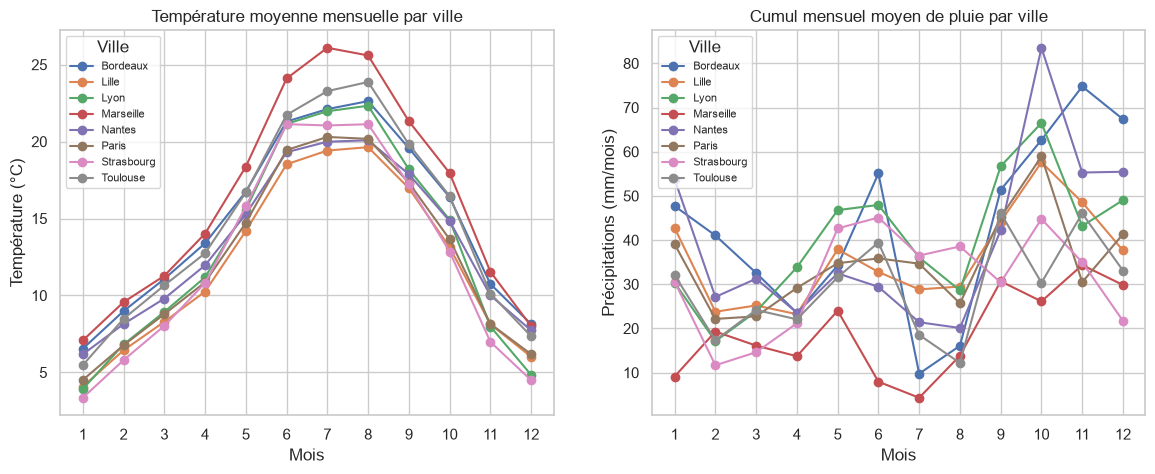

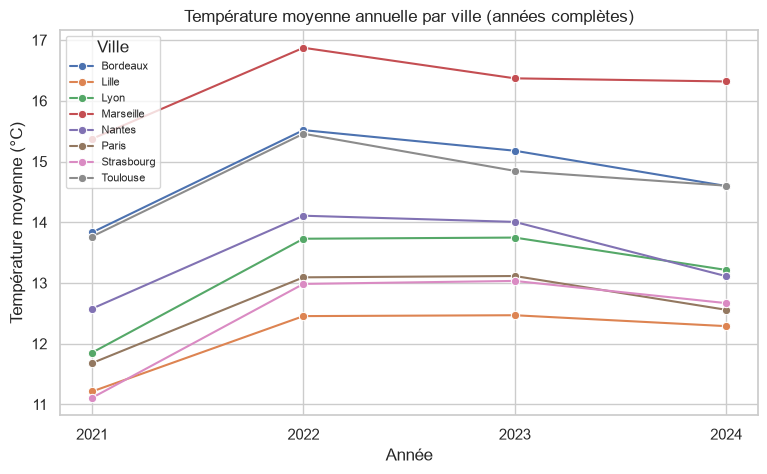

CHIFFRE CLÉ — amplitude mensuelle de température (°C) :
city
Bordeaux      16.1
Lille         15.6
Lyon          18.4
Marseille     19.0
Nantes        13.9
Paris         15.8
Strasbourg    17.8
Toulouse      18.4
dtype: float64

Tendance annuelle :
      city  n_annees  pente_C_par_an  p_value
  Bordeaux         4           0.195    0.658
     Lille         4           0.324    0.304
      Lyon         4           0.410    0.405
 Marseille         4           0.233    0.519
    Nantes         4           0.150    0.736
     Paris         4           0.265    0.490
Strasbourg         4           0.473    0.328
  Toulouse         4           0.190    0.650


In [7]:
df["month"] = df["local"].dt.month
clim_t = df.groupby(["city", "month"])[T].mean().unstack("city")
clim_p = (daily.groupby(["city", "year", "month"])["precip"].sum().groupby(["city", "month"]).mean().unstack("city"))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
clim_t.plot(ax=axes[0], marker="o"); axes[0].set(title="Température moyenne mensuelle par ville", xlabel="Mois", ylabel="Température (°C)")
clim_p.plot(ax=axes[1], marker="o"); axes[1].set(title="Cumul mensuel moyen de pluie par ville", xlabel="Mois", ylabel="Précipitations (mm/mois)")
for ax in axes: ax.set_xticks(range(1, 13)); ax.legend(title="Ville", fontsize=8)
save(fig, "q3_saisonnalite")

yearly = daily.groupby(["city", "year"]).agg(tmean=("tmean", "mean"), n=("tmean", "size")).reset_index()
yearly = yearly[yearly["n"] >= 330]
rows = []
for city, d in yearly.groupby("city"):
    if len(d) >= 3:
        r = stats.linregress(d["year"], d["tmean"]); rows.append((city, len(d), r.slope, r.pvalue))
trend = pd.DataFrame(rows, columns=["city", "n_annees", "pente_C_par_an", "p_value"]).round(3)

fig, ax = plt.subplots(figsize=(9, 5))
sns.lineplot(data=yearly, x="year", y="tmean", hue="city", marker="o", ax=ax)
ax.set(title="Température moyenne annuelle par ville (années complètes)", xlabel="Année", ylabel="Température moyenne (°C)")
ax.set_xticks(sorted(yearly["year"].unique())); ax.legend(title="Ville", fontsize=8)
save(fig, "q3_tendance_annuelle")
print("CHIFFRE CLÉ — amplitude mensuelle de température (°C) :"); print((clim_t.max() - clim_t.min()).round(1))
print("\nTendance annuelle :"); print(trend.to_string(index=False))

**Q3 — Méthode → chiffre clé → interprétation**
- Méthode : climatologie mensuelle par ville + régression linéaire annuelle (années complètes).
- Chiffre clé : [À COMPLÉTER : mois le plus chaud/froid, amplitude, pente °C/an Paris et p-value].
- Interprétation : [À COMPLÉTER en 2–3 phrases : saisonnalité nette ; tendance non significative sur 5 ans, à interpréter prudemment].

## Q4 — Jours extrêmes
**Méthode** : par ville, percentiles 1 et 99 des variables journalières (tmax, tmin, vent max, précipitations) ; un jour est extrême s'il dépasse ces seuils.

CHIFFRE CLÉ — nombre de jours extrêmes par type :
type
Journée très froide (tmax)    139
Chaleur extrême (tmax)        139
Nuit très chaude (tmin)       138
Nuit très froide (tmin)       137
Vent extrême                  136
Pluie extrême                 121
Name: count, dtype: int64

20 dernières dates extrêmes (à vérifier dans l'actualité, 2–3 dates) :


,city,date,type,valeur,seuil
4995,Lyon,2025-08-13,Chaleur extrême (tmax),38.7,36.3
6667,Marseille,2025-08-13,Chaleur extrême (tmax),36.7,36.7
10012,Paris,2025-08-13,Nuit très chaude (tmin),19.6,19.6
13350,Toulouse,2025-08-13,Chaleur extrême (tmax),38.8,37.8
4995,Lyon,2025-08-13,Nuit très chaude (tmin),21.5,21.3
10012,Paris,2025-08-13,Chaleur extrême (tmax),33.5,33.1
11679,Strasbourg,2025-08-13,Chaleur extrême (tmax),35.0,34.0
3324,Lille,2025-08-14,Nuit très chaude (tmin),20.0,19.0
6669,Marseille,2025-08-15,Chaleur extrême (tmax),37.5,36.7
11681,Strasbourg,2025-08-15,Chaleur extrême (tmax),35.0,34.0


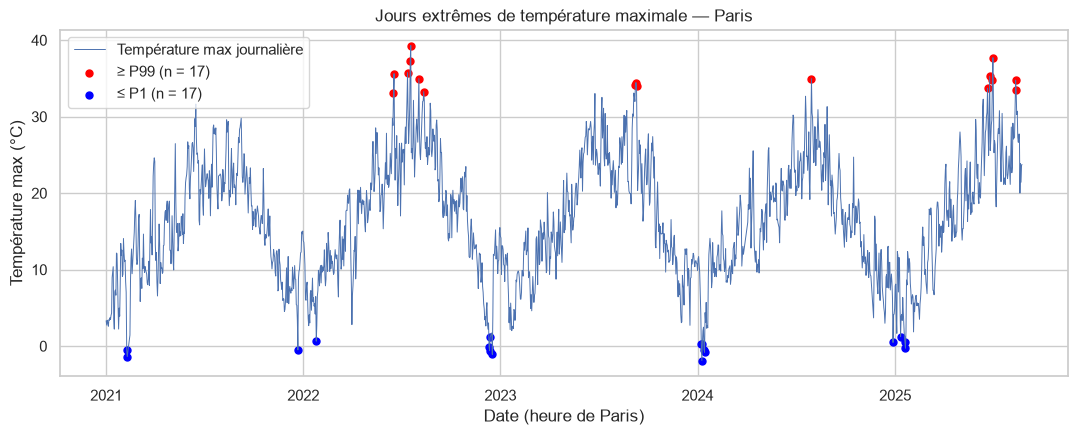

In [8]:
VARS = ["tmax", "tmin", "wind_max", "precip"]
for v in VARS:
    daily[f"{v}_p1"] = daily.groupby("city")[v].transform(lambda s: s.quantile(0.01))
    daily[f"{v}_p99"] = daily.groupby("city")[v].transform(lambda s: s.quantile(0.99))

rules = [("tmax", "p99", "Chaleur extrême (tmax)"), ("tmax", "p1", "Journée très froide (tmax)"),
         ("tmin", "p1", "Nuit très froide (tmin)"), ("tmin", "p99", "Nuit très chaude (tmin)"),
         ("wind_max", "p99", "Vent extrême"), ("precip", "p99", "Pluie extrême")]
events = []
for v, side, label in rules:
    thr = daily[f"{v}_{side}"]
    m = (daily[v] >= thr) if side == "p99" else (daily[v] <= thr)
    if v == "precip": m &= daily[v] > 0
    events.append(daily[m].assign(type=label, valeur=daily[v], seuil=thr)[["city", "date", "type", "valeur", "seuil"]])
ev = pd.concat(events).sort_values("date")

print("CHIFFRE CLÉ — nombre de jours extrêmes par type :"); print(ev["type"].value_counts())
last20 = ev.tail(20).round(1)
print("\n20 dernières dates extrêmes (à vérifier dans l'actualité, 2–3 dates) :")
display(last20)

pe = ev[ev["city"] == PARIS]
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(par["date"], par["tmax"], lw=0.7, label="Température max journalière")
hot = pe[pe["type"] == "Chaleur extrême (tmax)"]; cold = pe[pe["type"] == "Journée très froide (tmax)"]
ax.scatter(hot["date"], hot["valeur"], c="red", s=25, label=f"≥ P99 (n = {len(hot)})")
ax.scatter(cold["date"], cold["valeur"], c="blue", s=25, label=f"≤ P1 (n = {len(cold)})")
ax.set(title=f"Jours extrêmes de température maximale — {PARIS}", xlabel="Date (heure de Paris)", ylabel="Température max (°C)")
ax.legend(); save(fig, "q4_jours_extremes_paris")
last20.to_csv(FIG / "p1_q4_20_dernieres_dates.csv", index=False)

**Q4 — Méthode → chiffre clé → interprétation**
- Méthode : percentiles 1 et 99 par ville sur tmax, tmin, vent max, précipitations.
- Chiffre clé : [À COMPLÉTER : seuils P1/P99 de Paris, nombre de jours extrêmes, date vérifiée dans l'actualité].
- Interprétation : [À COMPLÉTER en 2–3 phrases : épisodes (canicule, tempête, vague de froid) retrouvés dans l'actualité].

In [9]:
# Contrôle final : toutes les figures de la partie 1 existent
figs = sorted(p.name for p in FIG.glob("p1_*.png")); print(len(figs), "figures :", figs)

7 figures : ['p1_q1_anomalies_paris.png', 'p1_q2_boxplot_visibilite_pluie.png', 'p1_q2_brouillard.png', 'p1_q2_heatmap_spearman.png', 'p1_q3_saisonnalite.png', 'p1_q3_tendance_annuelle.png', 'p1_q4_jours_extremes_paris.png']
